# Chain ground truth: detection proxies

Filings and closure announcements identify dated events, not individual final trading dates. Locations are chain + BBL, with missing BBLs mapped only to a unique same-chain address. Multiple operators can share a BBL. Alias lists and every location remain in reports/chain_results.json.

In [1]:
import os
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(root)
os.environ["OMP_NUM_THREADS"] = "4"
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from storefronts.gold import pipeline
from storefronts.notebook_tools import finish, style

style()

Dated corporate events provide external reference points, but are not final trading dates for every location. Cohorts include only chain locations observed positive before the event, so their coverage is conditional on prior inspection. Legal-name aliases and an independent court list help check how much of the observed coverage depends on business identity.

## Event cohorts and observation gaps

RadioShack includes GENERAL WIRELESS; Rite Aid includes GENOVESE DRUG STORE(S) and the observed DRUG SORES spelling; Payless requires PAYLESS SHOE SOURCE or PAYLESS SHOESOURCE, excluding generic PAYLESS. Each cohort requires a positive observation strictly before the event, within 365 or 730 days. Detection proxy = at least one subsequent OOB record / cohort locations. It does not identify which locations ceased trading on the event day.

Sources: [RadioShack 2015 filing](https://www.prnewswire.com/news-releases/radioshack-reaches-asset-purchase-agreement-with-affiliate-of-standard-general-to-acquire-up-to-2400-stores-300031940.html), [2017 court opinion](https://www.deb.uscourts.gov/sites/deb/files/opinions/gw-opinion-and-order_0.pdf), [Payless February 25, 2019 announcement](https://www.prnewswire.com/news-releases/payless-shoesource-conducting-store-closing-sales-at-all-stores-in-the-united-states-and-canada-300801293.html), [Rite Aid October 15, 2023 filing](https://www.sec.gov/Archives/edgar/data/84129/000110465923129388/tm2333722d1_8k.htm), [May 5, 2025 filing announcement](https://markets.financialcontent.com/statesmanexaminer/article/bizwire-2025-5-5-rite-aid-is-pursuing-a-strategic-and-value-maximizing-sale-process).

[{'$match': {'business.name_norm': {'$regex': '^(RADIO ?SHACK|GENERAL WIRELESS|RITE AID|GENOVESE '
                                              'DRUG|PAYLESS)'},
             'business_id': {'$ne': '', '$type': 'string'},
             'industry.is_storefront': True}},
 {'$project': {'address': 1,
               'bbl': 1,
               'business_id': 1,
               'business_key': 1,
               'inspected_at': 1,
               'is_closure': 1,
               'name': '$business.name_norm',
               'outcome': 1,
               'source': 1,
               'storefront_key': 1}},
 {'$sort': {'_id': 1, 'inspected_at': 1}}]


,chain,event,lookback_months,locations,post_event_oob,detection_proxy,positive_to_oob_days.n,positive_to_oob_days.min,positive_to_oob_days.p25,positive_to_oob_days.median,positive_to_oob_days.p75,positive_to_oob_days.p90,positive_to_oob_days.max,event_to_oob_days.n,event_to_oob_days.min,event_to_oob_days.p25,event_to_oob_days.median,event_to_oob_days.p75,event_to_oob_days.p90,event_to_oob_days.max
0,RadioShack incl General Wireless,2015-02-05,12,86,66,0.767442,66,0,392.50,505.0,718.50,885.5,2274,66,20,335.00,439.5,905.00,1167.0,2990
1,RadioShack incl General Wireless,2015-02-05,24,121,91,0.752066,91,0,412.50,601.0,859.00,1129.0,2274,91,20,311.00,426.0,929.00,1289.0,2990
2,RadioShack incl General Wireless,2017-03-08,12,18,16,0.888889,16,107,442.75,535.5,794.50,1718.0,2274,16,70,186.25,390.0,581.25,1538.0,2228
3,RadioShack incl General Wireless,2017-03-08,24,40,28,0.700000,28,107,493.00,710.0,920.50,1397.4,2274,28,70,209.50,360.5,567.50,834.5,2228
4,Payless ShoeSource,2019-02-25,12,29,21,0.724138,21,150,1728.00,2288.0,2442.00,2700.0,2805,21,52,1584.00,2095.0,2340.00,2500.0,2669
5,Payless ShoeSource,2019-02-25,24,59,44,0.745763,44,150,1708.75,2279.0,2588.25,2770.7,3259,44,52,1527.50,1880.5,2234.50,2468.5,2689
6,Rite Aid incl Genovese,2023-10-15,12,14,6,0.428571,6,262,583.75,780.0,983.00,1015.0,1043,6,82,639.25,661.5,755.00,902.0,1025
7,Rite Aid incl Genovese,2023-10-15,24,58,33,0.568966,33,262,971.00,1147.0,1273.00,1398.8,1648,33,82,648.00,754.0,851.00,995.0,1041
8,Rite Aid incl Genovese,2025-05-05,12,11,5,0.454545,5,485,490.00,567.0,582.00,619.8,645,5,227,345.00,435.0,457.00,465.4,471
9,Rite Aid incl Genovese,2025-05-05,24,23,10,0.434783,10,485,570.75,617.0,682.75,846.0,909,10,71,241.00,390.0,447.25,458.4,471


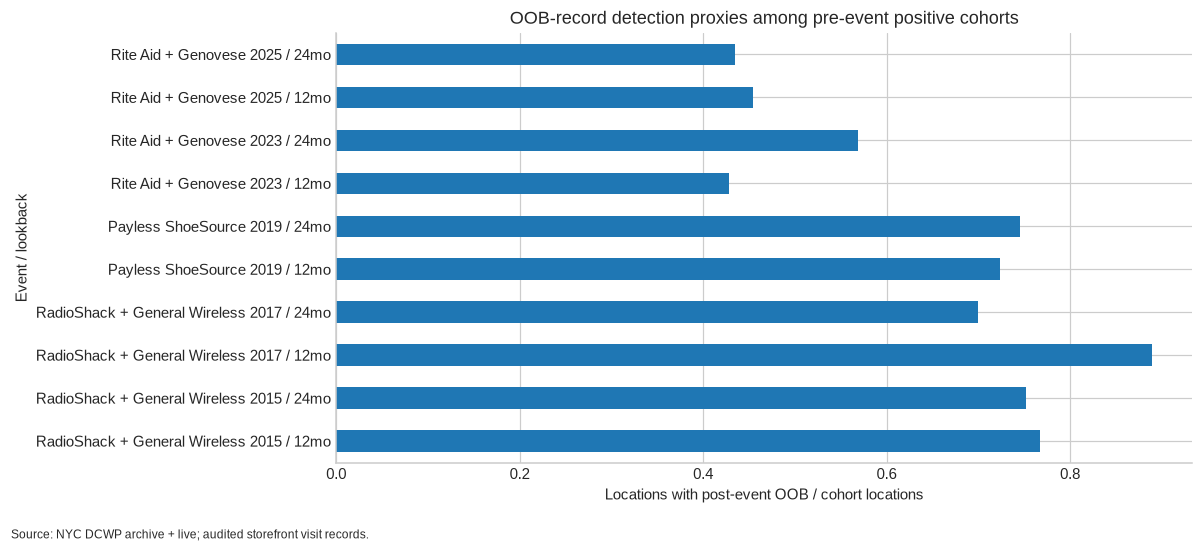

In [2]:
from pprint import pprint

from storefronts.chains import analyze

pprint(pipeline("chains.histories"), width=100)
chains = analyze()
cohorts = pd.json_normalize(chains["cohorts"])
display(cohorts)
labels = (
    cohorts.chain.str.replace(" incl ", " + ")
    + " "
    + pd.to_datetime(cohorts.event).dt.year.astype(str)
    + " / "
    + cohorts.lookback_months.astype(str)
    + "mo"
)
ax = cohorts.assign(label=labels).plot.barh(x="label", y="detection_proxy", legend=False)
finish(
    ax,
    "OOB-record detection proxies among pre-event positive cohorts",
    "Locations with post-event OOB / cohort locations",
    "Event / lookback",
)

Among locations with a positive in the year before each event, later OOB records appear for 66/86 RadioShack locations after February 2015 (76.7%), 16/18 after March 2017 (88.9%) and 21/29 Payless locations after February 2019 (72.4%). Rite Aid's October 2023 proxy is 6/14 with a 12-month lookback (42.9%) and 33/58 with 24 months (56.9%). On the same 86-location RadioShack cohort, adding General Wireless aliases raises detected locations from 51 to 66. Identity is therefore a major measurement issue. For the 2015 RadioShack cohorts, median last-positive-to-OOB gaps are 505 to 601 days; Payless medians are 2,279 to 2,288 days. These are coverage and observation-gap proxies among inspected locations, not actual shutdown latency or citywide detection rates.

## Records after chain closure periods

Bounds are January 2018 for RadioShack's 2017 mass closure period, January 2020 for Payless's 2019 North American closure program, and January 2026 for Rite Aid's 2025 closure program. RadioShack franchises and later brand activity prevent a universal company-wide cessation assumption.

Sources: [RadioShack May 2017 program](https://www.prnewswire.com/news-releases/last-chance-for-store-closing-deals-at-your-neighborhood-radioshack-come-innovate-with-us-one-last-time-300464748.html), [Rite Aid October 2025 report](https://apnews.com/article/4a5940f3eed4995fc7efce61f253fc8b). The source-query pipeline is displayed above and reused here.

,chain,cutoff,visit_records,oob,positive,other
0,RadioShack incl General Wireless,2018-01-01,48,47,0,1
1,Payless ShoeSource,2020-01-01,70,69,0,1
2,Rite Aid incl Genovese,2026-01-01,34,32,0,2


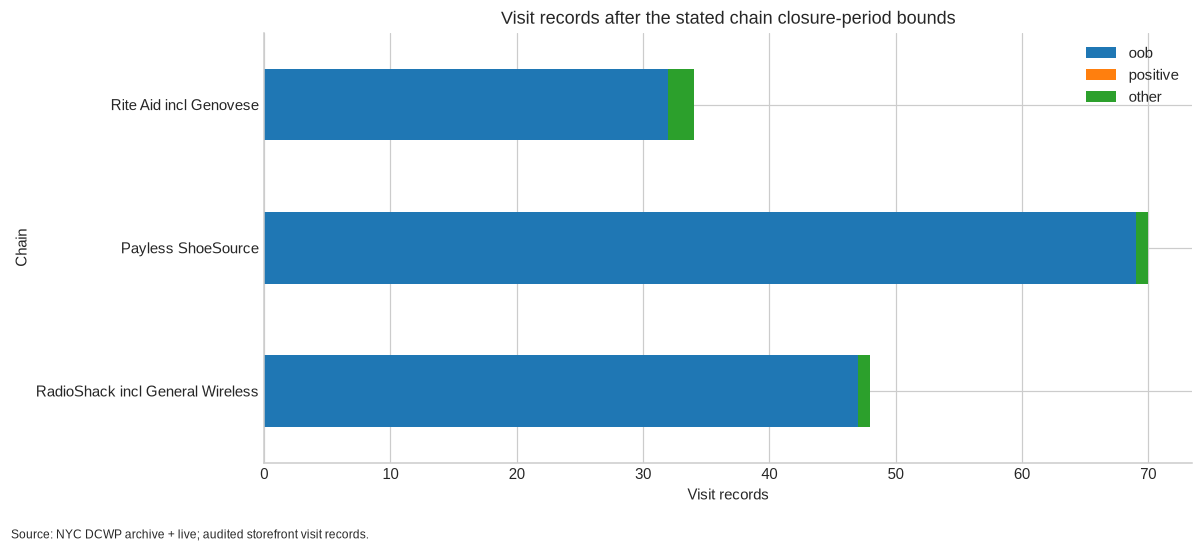

In [3]:
post = pd.DataFrame(chains["post_cutoff"])
display(post)
ax = post.set_index("chain")[["oob", "positive", "other"]].plot.barh(stacked=True)
finish(ax, "Visit records after the stated chain closure-period bounds", "Visit records", "Chain")

After the stated chain closure periods, inspection records continued. Payless ShoeSource records from 2020 onward contain 69 OOB visits and no positives; RadioShack and General Wireless records from 2018 onward contain 47 OOB visits and no positives. These are direct examples of OOB outcomes after dated closure programs. They do not establish each location's final trading date, and the RadioShack brand retained dealer and later activity.

## Independent seven-location Rite Aid court list

[Case 25-14861-MBK, Doc 743](https://npr.brightspotcdn.com/f8/c8/faad678e424db35665a541d7ce0a/25-06-06-store-closure-filing.pdf), printed pages 6, 7 and 75. This is a small selected NYC roster, not a complete chain census. A closure notice is not the final trading date. The Roosevelt Avenue address has two historical BBLs; exact-address candidates are explicitly unioned. Genovese aliases are retained.

,store,address,notice,pdf_page,matched_bbls,candidate_locations,last_seen,last_positive,first_oob_after_notice,notice_to_record_days
0,4873,55-60 MYRTLE AVENUE 11385,2025-05-09,75,[4035460060],1,2025-07-24 00:00:00,2022-06-17 14:30:03,2025-07-24,76.0
1,10577,8222 18TH AVENUE 11214,2025-05-09,75,[3063140072],1,2021-11-16 08:47:05,2021-11-16 08:47:05,NaT,NaN
2,3766,5901 BAY PARKWAY 11204,2025-05-09,75,[3065480001],1,2023-07-18 00:00:00,2023-07-18 00:00:00,NaT,NaN
3,10600,50-15 ROOSEVELT AVENUE 11377,2025-05-09,75,"[4013190021, 4013190030]",2,2026-02-04 00:00:00,2022-03-25 09:27:49,2026-02-04,271.0
4,10601,60-26 WOODSIDE AVENUE 11377,2025-05-09,75,[4013350041],1,2025-12-18 00:00:00,2024-05-30 00:00:00,2025-12-18,223.0
5,10585,2064 MILL AVENUE 11234,2025-06-06,6,[3084040002],1,2023-04-24 13:15:03,2023-04-24 13:15:03,NaT,NaN
6,2010,4046 BROADWAY 10032,2025-06-06,7,[1021410001],1,2025-10-15 00:00:00,2022-10-14 15:08:49,2025-10-15,131.0


Detected: 4 / 7 ; notice-to-record days: {'n': 4, 'min': 76, 'p25': 117.25, 'median': 177.0, 'p75': 235.0, 'p90': 256.6, 'max': 271}


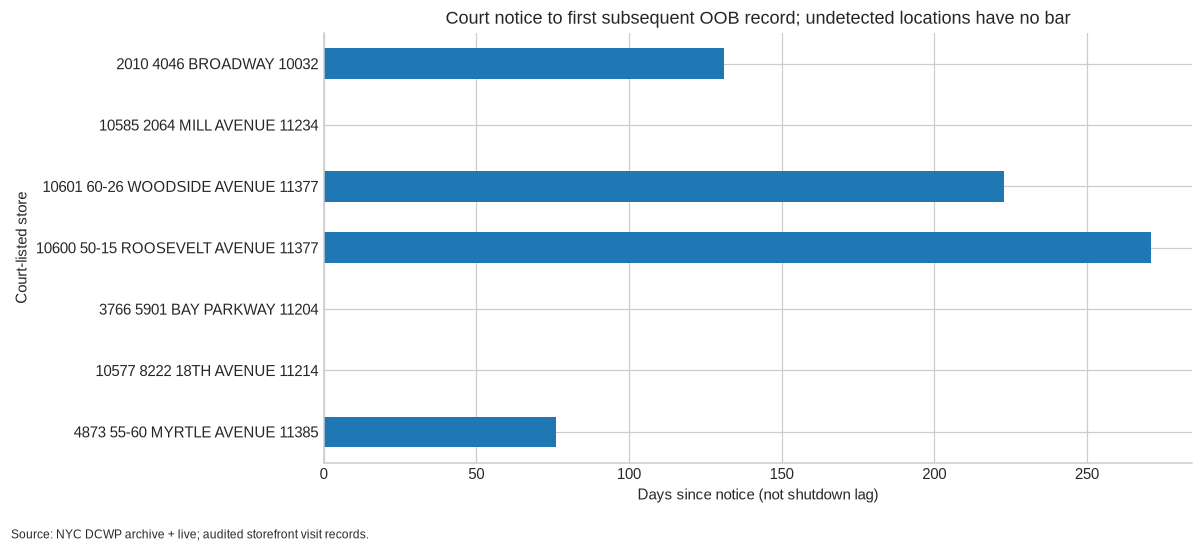

In [4]:
court = pd.DataFrame(chains["court"])
display(court)
print(
    "Detected:",
    chains["court_detected"],
    "/",
    len(court),
    "; notice-to-record days:",
    chains["court_notice_gap"],
)
ax = court.assign(label=court.store + " " + court.address).plot.barh(
    x="label", y="notice_to_record_days", legend=False
)
finish(
    ax,
    "Court notice to first subsequent OOB record; undetected locations have no bar",
    "Days since notice (not shutdown lag)",
    "Court-listed store",
)

The selected court roster lists seven NYC Rite Aid stores. Four received an OOB record after the notice, at 76, 131, 223 and 271 days (median 177); three stopped appearing in inspections before the notice. This is the independent denominator here, but seven selected locations cannot establish a chain-wide detection rate. The result is consistent with incomplete, delayed recording in the cohort proxies. Notice dates are not actual shutdown dates, so these gaps measure time since notice rather than closure latency.

## Location timelines

Last positive and first OOB dates are observed inspection outcomes; an OOB may precede a later positive. Every location is shown, without inferring an individual shutdown date. Underlying source pipeline: chains.histories.

,chain,location,address,last_seen,last_positive,first_closure,last_closure,positive_to_first_closure_days
0,RadioShack incl General Wireless,ADDR:10001|901|AMERICAS,901 AMERICAS 10001,2015-10-23 12:28:00,2015-10-23 12:28:00,NaT,NaT,NaN
1,RadioShack incl General Wireless,ADDR:10019|209|CENTRAL PARK S,209 CENTRAL PARK S 10019,2010-03-04 00:00:00,2010-03-04 00:00:00,NaT,NaT,NaN
2,RadioShack incl General Wireless,ADDR:10034|315|W 205TH ST,315 W 205TH ST 10034,2016-09-28 19:37:00,NaT,2016-09-28 19:37:00,2016-09-28 19:37:00,NaN
3,RadioShack incl General Wireless,ADDR:10457|587|E TREMONT AVE,587 E TREMONT AVE 10457,2020-03-06 00:00:00,2017-04-17 12:29:00,2020-01-28 12:00:00,2020-03-06 00:00:00,1015.0
4,RadioShack incl General Wireless,ADDR:10466|1213A|E 233RD ST,1213A E 233RD ST 10466,2015-08-27 11:46:00,2015-08-27 11:46:00,NaT,NaT,NaN
...,...,...,...,...,...,...,...,...
521,Rite Aid incl Genovese,BBL:5004880065,385 BAY ST 10301,2023-05-19 12:08:50,2018-08-17 00:00:00,2023-05-19 12:08:50,2023-05-19 12:08:50,1736.0
522,Rite Aid incl Genovese,BBL:5023800040,None RICHMOND AVE 10314,2024-12-31 00:00:00,2022-09-14 09:57:15,2024-12-31 00:00:00,2024-12-31 00:00:00,838.0
523,Rite Aid incl Genovese,BBL:5033460016,1360 HYLAN BLVD 10305,2016-04-01 11:36:00,2013-08-22 00:00:00,2011-02-09 00:00:00,2016-04-01 11:36:00,NaN
524,Rite Aid incl Genovese,BBL:5054950065,None AMBOY RD 10312,2026-08-20 00:00:00,2024-01-31 00:00:00,2013-05-11 00:00:00,2026-08-20 00:00:00,118.0


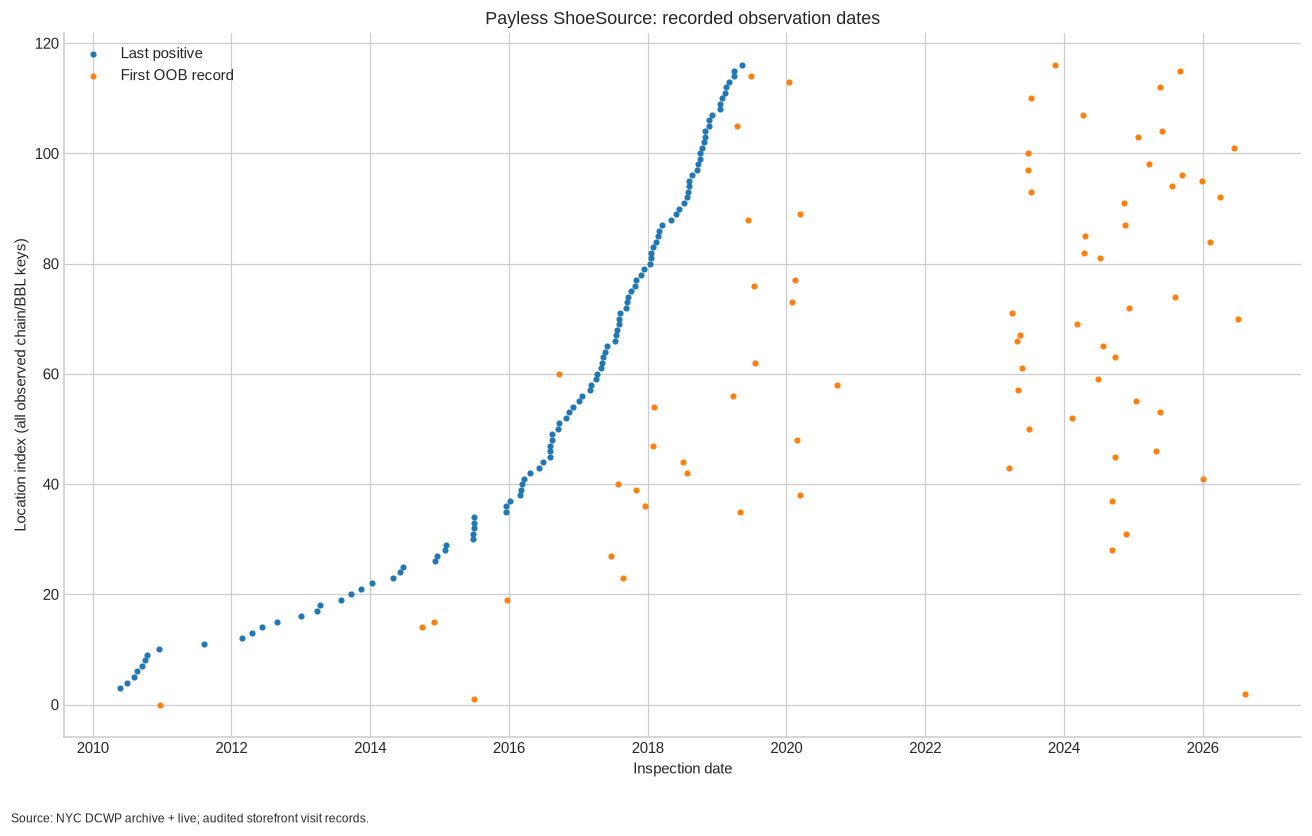

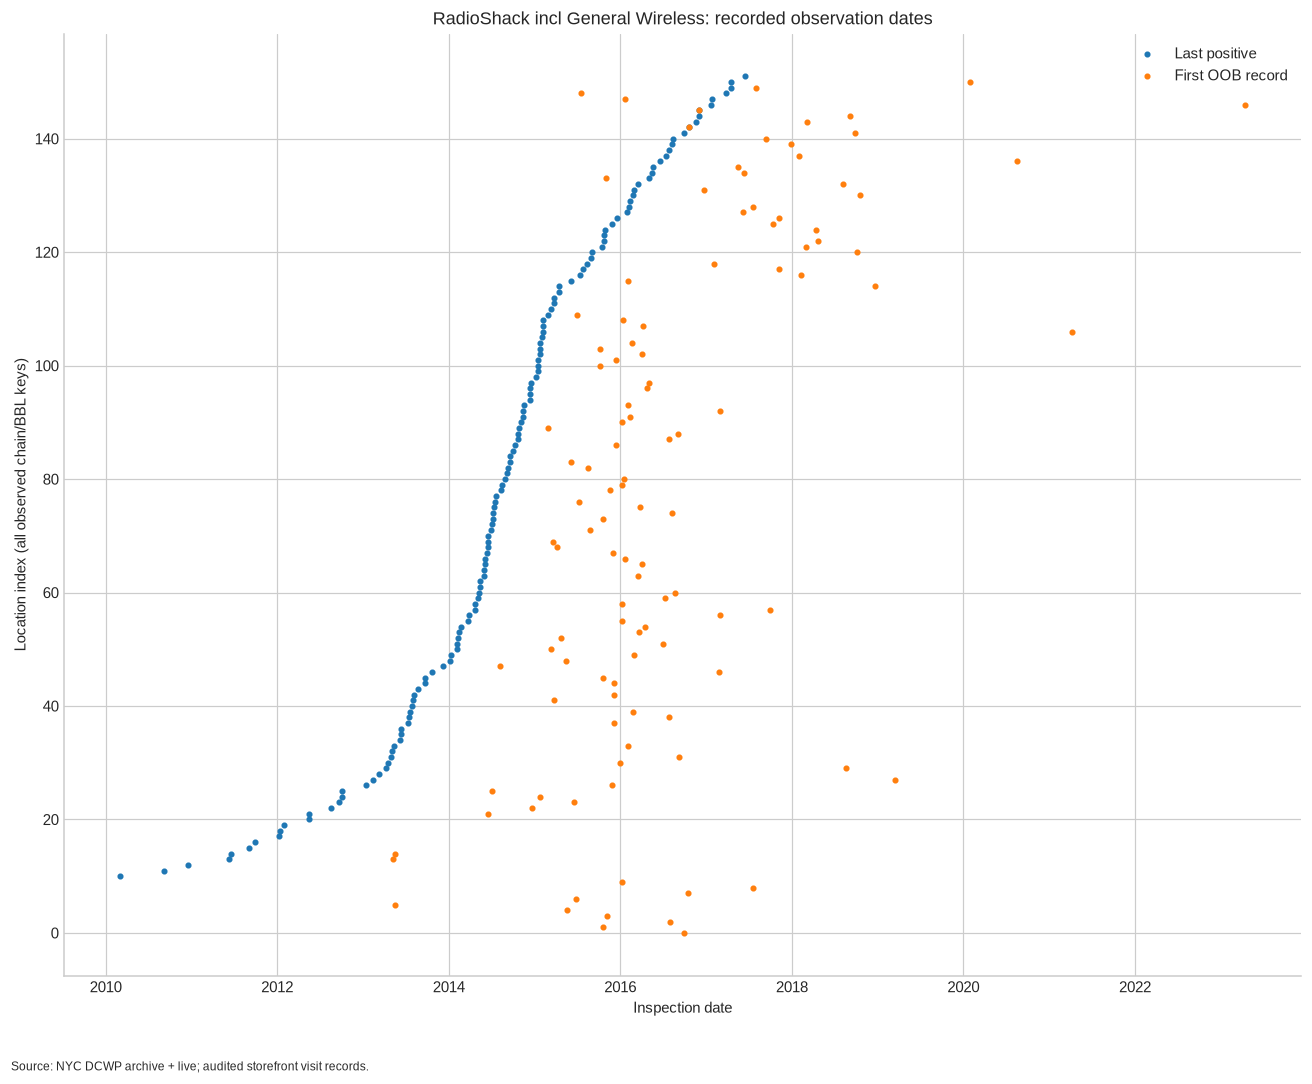

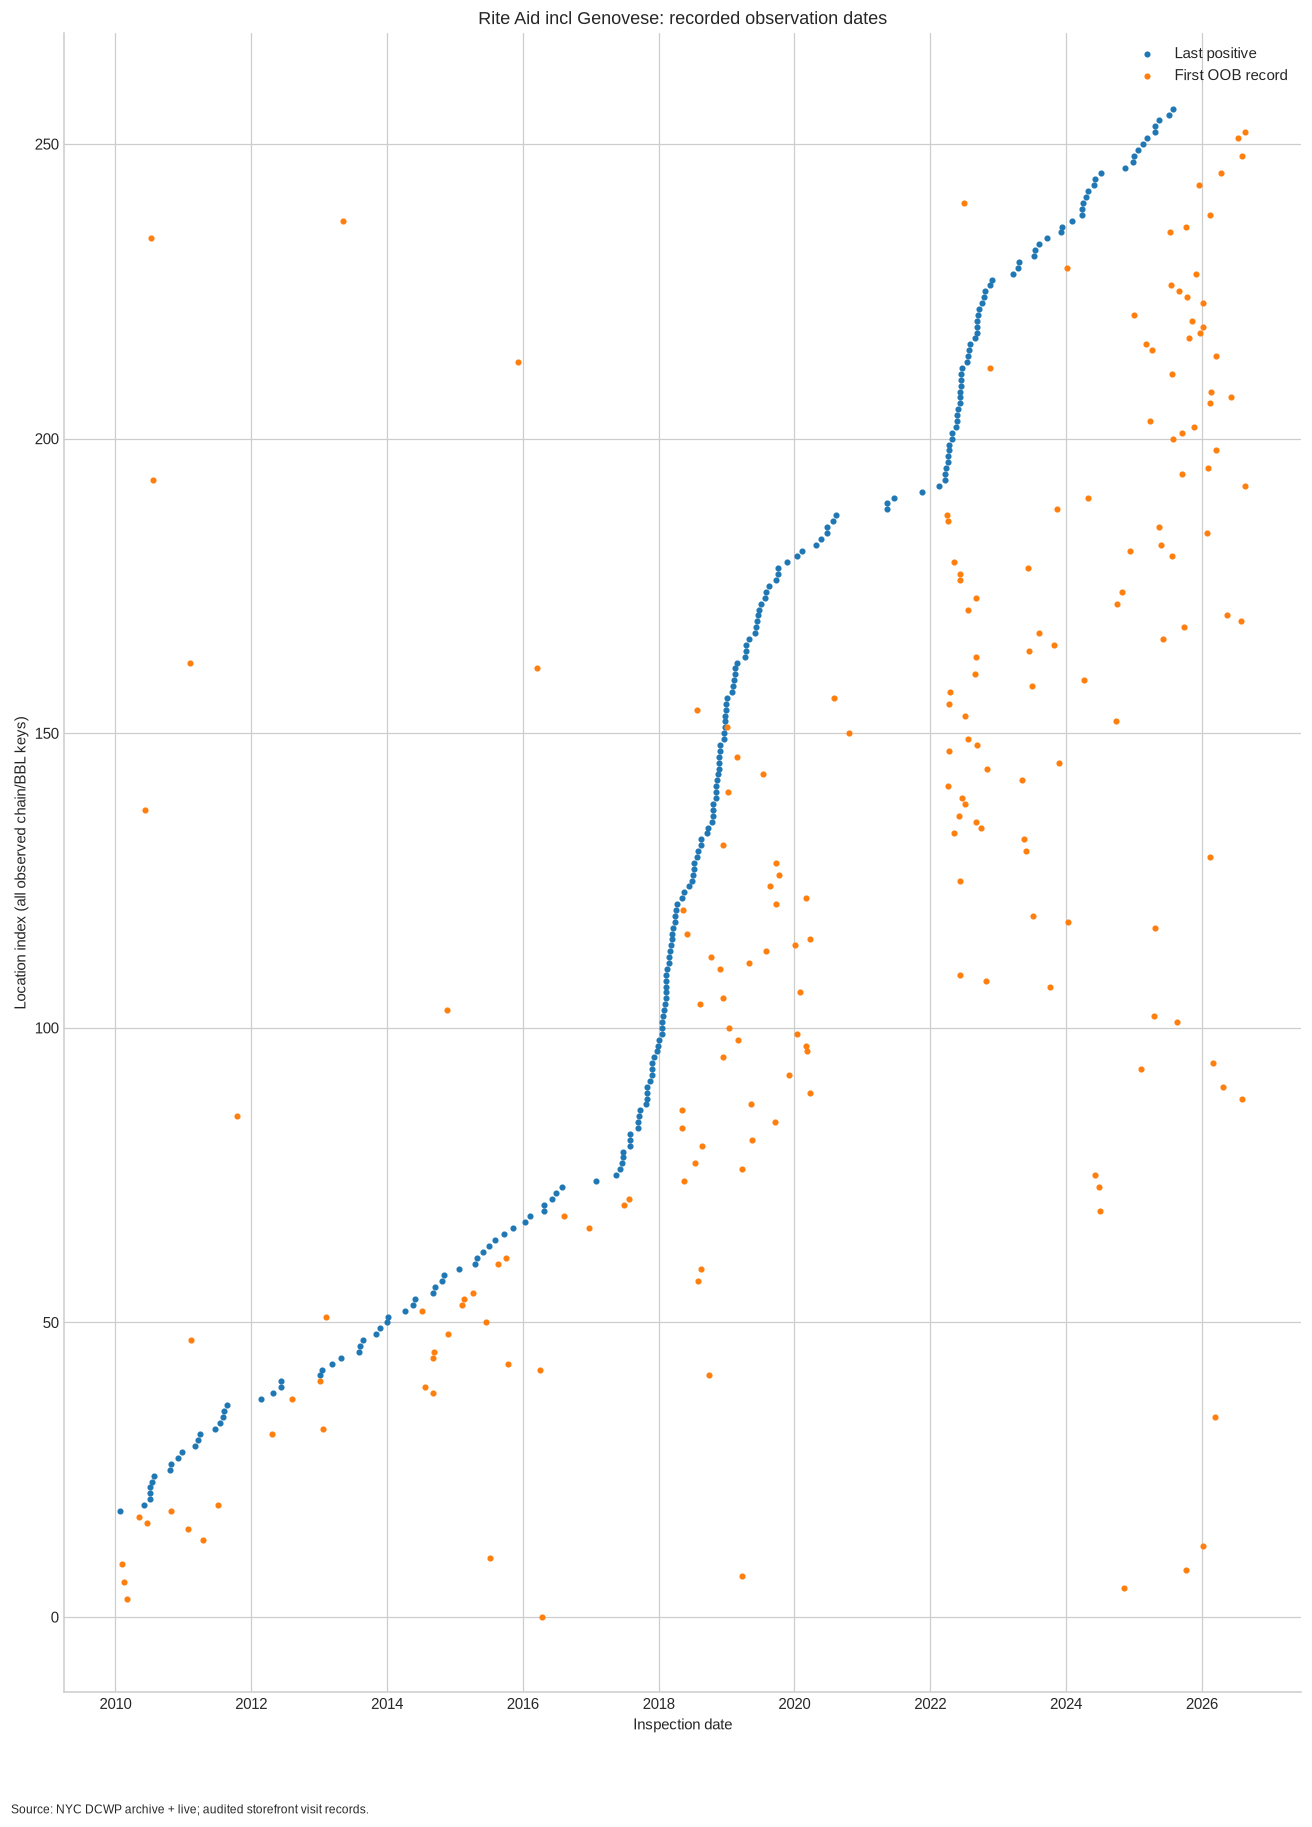

In [5]:
timeline = pd.DataFrame(chains["timelines"])
display(timeline)
for chain, f in timeline.groupby("chain", sort=True):
    f = f.sort_values(["last_positive", "location"], na_position="first").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, max(5, len(f) * 0.065)))
    ax.scatter(pd.to_datetime(f.last_positive), f.index, s=9, label="Last positive")
    ax.scatter(pd.to_datetime(f.first_closure), f.index, s=9, label="First OOB record")
    ax.legend()
    finish(
        ax,
        chain + ": recorded observation dates",
        "Inspection date",
        "Location index (all observed chain/BBL keys)",
    )

The timelines contain last positive observations and OOB records separated by months to years. They do not establish that positives stopped on the corporate event date or identify each location's actual shutdown date. An OOB finding depends on a subsequent recorded inspection opportunity, so the observation date cannot be treated as the date the business ceased operating.